# BigMart Data Preparation

This notebook handles the preparation stage for the BigMart project.

The goal is to load `Train.csv` and `Test.csv`, explore the training data, clean both datasets in a consistent way, apply the same feature engineering, and save prepared files for modeling later.

## 1. Imports

Only the libraries needed for preparation and basic exploration are used here.

In [1]:
from pathlib import Path

import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

# The BigMart sales data was collected in 2013, so outlet age is measured
# relative to that year (not the current year). Used for train and test alike.
REFERENCE_YEAR = 2013

## 2. Load Train and Test Data

Both files are loaded here, but the main exploration is done on the training set because that is the dataset with the target column.

In [2]:
train_df = pd.read_csv("Train.csv")
test_df = pd.read_csv("Test.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

Train shape: (8523, 12)
Test shape: (5681, 11)


In [3]:
train_df.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 3. Quick Exploration of the Training Data

This section keeps the exploration simple and focused on what matters before cleaning.

In [4]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [5]:
train_missing = pd.DataFrame({
    "missing_count": train_df.isna().sum(),
    "missing_percent": (train_df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

train_missing

,missing_count,missing_percent
Outlet_Size,2410,28.28
Item_Weight,1463,17.17
Item_Identifier,0,0.00
Item_Fat_Content,0,0.00
Item_Visibility,0,0.00
Item_Type,0,0.00
Item_MRP,0,0.00
Outlet_Identifier,0,0.00
Outlet_Establishment_Year,0,0.00
Outlet_Location_Type,0,0.00


In [6]:
train_df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35
Item_Fat_Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item_Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item_MRP,8523.0,NaN,NaN,NaN,140.992782,62.275067,31.29,93.8265,143.0128,185.6437,266.8884
Outlet_Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Establishment_Year,8523.0,NaN,NaN,NaN,1997.831867,8.37176,1985.0,1987.0,1999.0,2004.0,2009.0
Outlet_Size,6113,3,Medium,2793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet_Location_Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


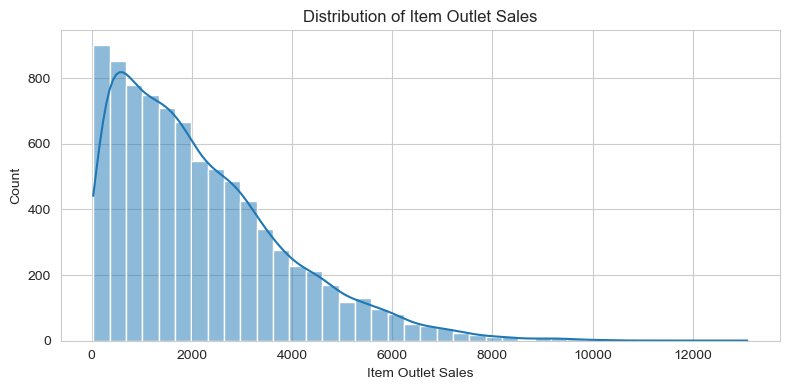

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(train_df["Item_Outlet_Sales"], bins=40, kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.xlabel("Item Outlet Sales")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## 4. Cleaning and Feature Engineering Functions

The same preparation logic is used for both datasets.

For the test set, values are filled using information learned from the training data so that the process stays consistent.

A few details keep train and test features meaning the same thing:
- Zero visibilities are treated as missing and filled from the item's average over its non-zero training rows. Train and test use the same table.
- `Item_Visibility_Mean` never includes the row itself. In training it is the item's average over its *other* rows (leave-one-out), just as a test row's average comes only from training rows.
- `Outlet_Age` is measured from `REFERENCE_YEAR` (2013, when the data was collected).

In [8]:
FAT_CONTENT_FIXES = {
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
}

ITEM_CATEGORY_MAP = {
    "FD": "Food",
    "NC": "Non-Consumable",
    "DR": "Drinks"
}


def learn_visibility_stats(raw_df: pd.DataFrame):
    """Learn per-item and overall visibility from RAW rows with visibility > 0.

    A visibility of 0 means "missing", so those rows must not pull the
    averages down. Train and test both use this same table to fill zeros.
    """
    nonzero_rows = raw_df.loc[raw_df["Item_Visibility"] > 0]
    item_visibility_map = nonzero_rows.groupby("Item_Identifier")["Item_Visibility"].mean()
    overall_visibility_median = nonzero_rows["Item_Visibility"].median()
    return item_visibility_map, overall_visibility_median


def leave_one_out_visibility_mean(raw_df: pd.DataFrame, overall_visibility_median: float) -> pd.Series:
    """For each training row, the item's average visibility over its OTHER rows.

    A test row's Item_Visibility_Mean comes only from training rows, never from
    the row itself. Excluding the row itself in training gives the feature the
    same meaning there. Items with no other non-zero rows get the overall
    median, the same fallback that unseen items get in the test data.
    """
    nonzero_visibility = raw_df["Item_Visibility"].where(raw_df["Item_Visibility"] > 0)
    item_groups = nonzero_visibility.groupby(raw_df["Item_Identifier"])
    item_sum = item_groups.transform("sum")
    item_count = item_groups.transform("count")

    own_value = nonzero_visibility.fillna(0)
    own_count = nonzero_visibility.notna().astype(int)
    other_count = item_count - own_count

    loo_mean = (item_sum - own_value) / other_count.where(other_count > 0)
    return loo_mean.fillna(overall_visibility_median)


def learn_outlet_size_map(df: pd.DataFrame):
    """Most common Outlet_Size per Outlet_Type, plus an overall fallback size.

    An Outlet_Type whose sizes are all missing has no mode, so it gets the
    overall most common size instead of crashing.
    """
    overall_modes = df["Outlet_Size"].mode()
    overall_size = overall_modes.iloc[0] if not overall_modes.empty else "Unknown"

    def most_common_size(sizes: pd.Series):
        modes = sizes.mode()
        return modes.iloc[0] if not modes.empty else overall_size

    outlet_size_map = df.groupby("Outlet_Type")["Outlet_Size"].agg(most_common_size)
    return outlet_size_map, overall_size


def fill_outlet_size(clean_df: pd.DataFrame, outlet_size_map: pd.Series, overall_size: str) -> pd.Series:
    return (
        clean_df["Outlet_Size"]
        .fillna(clean_df["Outlet_Type"].map(outlet_size_map))
        .fillna(overall_size)
    )


def add_shared_features(clean_df: pd.DataFrame) -> pd.DataFrame:
    clean_df["Item_Category"] = clean_df["Item_Identifier"].str[:2].map(ITEM_CATEGORY_MAP)
    clean_df.loc[clean_df["Item_Category"] == "Non-Consumable", "Item_Fat_Content"] = "Non-Edible"
    clean_df["Outlet_Age"] = REFERENCE_YEAR - clean_df["Outlet_Establishment_Year"]
    return clean_df


def clean_train_data(df: pd.DataFrame) -> pd.DataFrame:
    clean_df = df.copy()

    clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace(FAT_CONTENT_FIXES)

    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
        clean_df.groupby("Item_Identifier")["Item_Weight"].transform("mean")
    )
    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
        clean_df.groupby("Item_Type")["Item_Weight"].transform("mean")
    )

    outlet_size_map, overall_size = learn_outlet_size_map(clean_df)
    clean_df["Outlet_Size"] = fill_outlet_size(clean_df, outlet_size_map, overall_size)

    item_visibility_map, overall_visibility_median = learn_visibility_stats(df)
    zero_visibility_mask = clean_df["Item_Visibility"] == 0
    replacement_visibility = clean_df["Item_Identifier"].map(item_visibility_map).fillna(overall_visibility_median)
    clean_df.loc[zero_visibility_mask, "Item_Visibility"] = replacement_visibility[zero_visibility_mask]

    clean_df = add_shared_features(clean_df)

    clean_df["Item_Visibility_Mean"] = leave_one_out_visibility_mean(df, overall_visibility_median)
    clean_df["Visibility_Ratio"] = clean_df["Item_Visibility"] / clean_df["Item_Visibility_Mean"]

    return clean_df


def clean_test_data(df: pd.DataFrame, train_reference: pd.DataFrame, train_raw: pd.DataFrame) -> pd.DataFrame:
    """Clean new data using only statistics learned from the training data.

    train_reference is the prepared (cleaned) training data.
    train_raw is the same training rows before cleaning; it is needed so that
    zero visibilities are filled from exactly the same table as in training.
    """
    clean_df = df.copy()
    reference_df = train_reference.copy()

    clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace(FAT_CONTENT_FIXES)

    item_weight_map = reference_df.groupby("Item_Identifier")["Item_Weight"].mean()
    item_type_weight_map = reference_df.groupby("Item_Type")["Item_Weight"].mean()
    outlet_size_map, overall_size = learn_outlet_size_map(reference_df)
    item_visibility_map, overall_visibility_median = learn_visibility_stats(train_raw)

    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(clean_df["Item_Identifier"].map(item_weight_map))
    clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(clean_df["Item_Type"].map(item_type_weight_map))

    clean_df["Outlet_Size"] = fill_outlet_size(clean_df, outlet_size_map, overall_size)

    zero_visibility_mask = clean_df["Item_Visibility"] == 0
    replacement_visibility = clean_df["Item_Identifier"].map(item_visibility_map).fillna(overall_visibility_median)
    clean_df.loc[zero_visibility_mask, "Item_Visibility"] = replacement_visibility[zero_visibility_mask]

    clean_df = add_shared_features(clean_df)

    clean_df["Item_Visibility_Mean"] = clean_df["Item_Identifier"].map(item_visibility_map).fillna(overall_visibility_median)
    clean_df["Visibility_Ratio"] = clean_df["Item_Visibility"] / clean_df["Item_Visibility_Mean"]

    return clean_df

## 5. Apply the Preparation to Train and Test

The training data is cleaned first, and then the same logic is applied to the test data using the training set as reference.

In [9]:
prepared_train = clean_train_data(train_df)
prepared_test = clean_test_data(test_df, prepared_train, train_df)

print("Prepared train shape:", prepared_train.shape)
print("Prepared test shape:", prepared_test.shape)

Prepared train shape: (8523, 16)
Prepared test shape: (5681, 15)


In [10]:
print("Prepared train missing values:", int(prepared_train.isna().sum().sum()))
print("Prepared test missing values:", int(prepared_test.isna().sum().sum()))

Prepared train missing values: 0
Prepared test missing values: 0


In [11]:
prepared_train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Item_Category,Outlet_Age,Item_Visibility_Mean,Visibility_Ratio
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,Food,14,0.017578,0.912912
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,Drinks,4,0.019208,1.003670
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,Food,14,0.020709,0.809327
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,Food,15,0.022911,1.000000
4,NCD19,8.93,Non-Edible,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,Non-Consumable,26,0.016164,1.000000


## 6. Save the Prepared Files

These saved files will be used in the second notebook for modeling and final prediction.

In [12]:
prepared_train.to_csv("prepared_train.csv", index=False)
prepared_test.to_csv("prepared_test.csv", index=False)

print("Saved prepared_train.csv")
print("Saved prepared_test.csv")

Saved prepared_train.csv
Saved prepared_test.csv


## 7. Prepare a Leak-Free Train/Validation Split

The modeling notebook needs a validation set to compare and tune models.
If that split were made **after** cleaning, the validation rows would already have shaped the fill values and per-item features (`Item_Weight` fills, zero-visibility fills, `Item_Visibility_Mean`, `Visibility_Ratio`), and the validation scores would look better than they really are.

So the raw training data is split first. The training part is cleaned on its own, and the validation part is cleaned like the test set, using only statistics learned from the training part.

In [13]:
train_part_raw, valid_part_raw = train_test_split(
    train_df,
    test_size=0.2,
    random_state=RANDOM_STATE
)

prepared_train_part = clean_train_data(train_part_raw)
prepared_valid_part = clean_test_data(valid_part_raw, prepared_train_part, train_part_raw)

print("Prepared train part shape:", prepared_train_part.shape)
print("Prepared validation part shape:", prepared_valid_part.shape)
print("Train part missing values:", int(prepared_train_part.isna().sum().sum()))
print("Validation part missing values:", int(prepared_valid_part.isna().sum().sum()))

prepared_train_part.to_csv("prepared_train_part.csv", index=False)
prepared_valid_part.to_csv("prepared_valid_part.csv", index=False)

print("Saved prepared_train_part.csv")
print("Saved prepared_valid_part.csv")

Prepared train part shape: (6818, 16)
Prepared validation part shape: (1705, 16)
Train part missing values: 0
Validation part missing values: 0


Saved prepared_train_part.csv
Saved prepared_valid_part.csv
